# Image Warping Lab


## Part 1: Interpolation

Since we are going to be warping images, we need to make sure we have a good interpolation function to deal with inexact pixel locations.

In the cell below, we want to scale an image by a factor of 2.30 in both x and y. **Write a function called "interpolate" that performs bilinear interpolation.** This function should take in the image and a location (x,y) of interest. It then uses the nearby pixels to interpolate and return an RGB value.

**Note:** For this lab, we will keep images as floats to simplify the interpolation. Thus, output your images as values between 0-1, not 0-255.


0.99215686


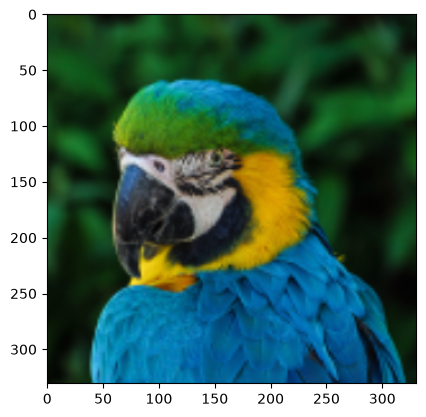

In [17]:
import matplotlib.pyplot as plt
import numpy as np

#Your bilinear interpolation function
# We look at the 4 surrounding integer pixels and weight them by distance.
def interpolate(image, x, y):
    
    h, w, _ = image.shape

    # Integer coordinates of the top-left neighbor
    x0 = int(np.floor(x))
    y0 = int(np.floor(y))
    # Bottom-right neighbors are one pixel over
    x1 = x0 + 1
    y1 = y0 + 1

    # Fractional distances from the top-left pixel (0 <= dx,dy < 1)
    dx = x - np.floor(x)
    dy = y - np.floor(y)

    # Clip to image bounds so edge queries don't go out of range.
    # compose() already skips fully out-of-bounds points, this just handles the x1/y1 = edge+1 case safely.
    x0 = np.clip(x0, 0, w-1)
    x1 = np.clip(x1, 0, w-1)
    y0 = np.clip(y0, 0, h-1)
    y1 = np.clip(y1, 0, h-1)

    # Grab the four neighbors
    top_left     = image[y0, x0]
    top_right    = image[y0, x1]
    bottom_left  = image[y1, x0]
    bottom_right = image[y1, x1]

    # Interpolate horizontally on the top and bottom rows
    top    = (1 - dx) * top_left  + dx * top_right
    bottom = (1 - dx) * bottom_left + dx * bottom_right
    # then interpolate those two results vertically
    result = (1 - dy) * top + dy * bottom

    return result



filename = "test.png"
im = plt.imread(filename)

print(np.amax(im)) #Image values should be between 0-1, not 0-255

h,w,_ = im.shape

result = np.zeros((int(2.3*h),(int(2.3*w)),3), dtype="float32")

rows, cols, _ = result.shape

# Map each new point back to the original image
for i in range(rows):
    for j in range(cols):
        result[i,j] = interpolate(im, j/2.3, i/2.3)

        
plt.imshow(result,vmin=0)
plt.show()

## Part 2: Homographies

Now that we have a interpolation function, we are ready to start implementing perspective warp. We provide two vital functions for you: a compose function and a homography matrix generator.

The compose function maps a source image onto a target image given a transform using backwards mapping. In Lab 3, we used Pillow's built-in compose function. We implement this function ourselves here, but **this function calls your interpolate function, so if it is not working, there may be something wrong with your interpolate function.**

As a reminder, backwards mapping takes the following steps:

- Invert the given transformation.
- For each pixel in the target image
  - Determine the x and y coordinates of the pixel
  - Homogenize the coordinate
  - Multiply it by the inverse transform
  - Perform the homogenous divide on the new point
  - If the x,y coordinate is within the boundaries of the source image, grab the interpolated value from source image. Otherwise, keep the original pixel in the target image.


In [18]:
def compose(source_im,target_im,transform):
    
    hs,ws,_ = source_im.shape
    ht,wt,_ = target_im.shape
    result = np.copy(target_im)
    
    invtransform = np.linalg.inv(transform)
    
    for i in range(ht):
        for j in range(wt):
            h_pt = np.matrix([[j],[i],[1]])
            c_pt = invtransform*h_pt
            x = c_pt[0,0]/c_pt[2,0]
            y = c_pt[1,0]/c_pt[2,0]

            if x < 0 or x >= ws or y < 0 or y >= hs:
                continue

            result[i,j]=interpolate(source_im,x,y)

    return result

Again, in this lab, we have also provided the homography generating code for you.


In [19]:
class Point():
    def __init__(self,x,y):
        self.x = x
        self.y = y

    def __str__(self):
        return "({},{})".format(self.x,self.y)
    
    def __repr__(self):
        return self.__str__()


def getHomography(s0,s1,s2,s3,t0,t1,t2,t3):

    x0s = s0.x
    y0s = s0.y
    x0t = t0.x
    y0t = t0.y

    x1s = s1.x
    y1s = s1.y
    x1t = t1.x
    y1t = t1.y

    x2s = s2.x
    y2s = s2.y
    x2t = t2.x
    y2t = t2.y

    x3s = s3.x
    y3s = s3.y
    x3t = t3.x
    y3t = t3.y

    #Solve for the homography matrix
    A = np.matrix([
            [x0s, y0s, 1, 0, 0, 0, -x0t*x0s, -x0t*y0s],
            [0, 0, 0, x0s, y0s, 1, -y0t*x0s, -y0t*y0s],
            [x1s, y1s, 1, 0, 0, 0, -x1t*x1s, -x1t*y1s],
            [0, 0, 0, x1s, y1s, 1, -y1t*x1s, -y1t*y1s],
            [x2s, y2s, 1, 0, 0, 0, -x2t*x2s, -x2t*y2s],
            [0, 0, 0, x2s, y2s, 1, -y2t*x2s, -y2t*y2s],
            [x3s, y3s, 1, 0, 0, 0, -x3t*x3s, -x3t*y3s],
            [0, 0, 0, x3s, y3s, 1, -y3t*x3s, -y3t*y3s]
        ])

    b = np.matrix([
            [x0t],
            [y0t],
            [x1t],
            [y1t],
            [x2t],
            [y2t],
            [x3t],
            [y3t]
        ])

    #The homorgraphy solutions a-h
    solutions = np.linalg.solve(A,b)

    solutions = np.append(solutions,[[1.0]], axis=0)

    #Reshape the homography into the appropriate 3x3 matrix
    homography = np.reshape(solutions, (3,3))
    
    return homography

We want to be able to get a new image into the TV set in the image shown below.

To place the bird correctly inside the image, do the following:

- Determine the homography that maps from the bird image to the TV. Use the `getHomography` function and the provided points.

- For each pixel/point within the target image, backmap those points onto the bird image. Use your `compose` function and make sure it correctly rejects points that do not land within the image boundary

Write a general perspective warp function that completes these steps. **Hint: If your interpolate is written correctly, this should only be 2-3 lines of code.**


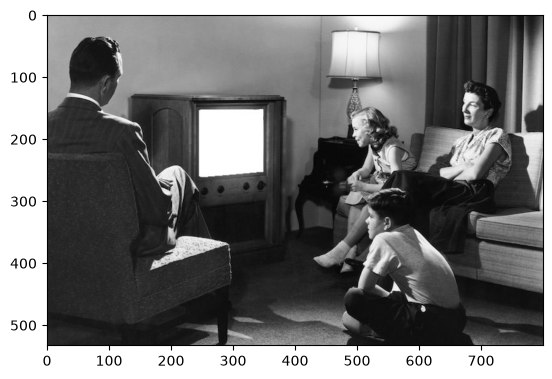

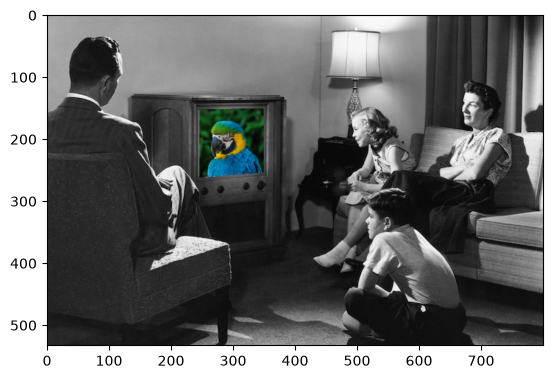

In [32]:
def perspectiveWarp(source_im,target_im,s0,s1,s2,s3,t0,t1,t2,t3):
    
    result = np.copy(target_im)
    
    # Your code here
    H = getHomography(s0,s1,s2,s3,t0,t1,t2,t3)
    result = compose(source_im, target_im, H)
  
    return result
    

filename = "test.png"
im = plt.imread(filename)

h,w,_ = im.shape
        
s0 = Point(0,0)
s1 = Point(w-1,0)
s2 = Point(w-1,h-1)
s3 = Point(0,h-1)

t0 = Point(245,152)
t1 = Point(349,150)
t2 = Point(349,253)
t3 = Point(246,261)

tv = plt.imread('tv.png')
plt.imshow(tv,vmin=0)
plt.show()

result = perspectiveWarp(im,tv,s0,s1,s2,s3,t0,t1,t2,t3)

plt.imshow(result,vmin=0)
plt.show()


# Part 3: Speed Up

We have a complete perspective warping algorithm now, but you may have noticed that it runs a little slowly. This is because it checks every pixel in the target image to see if it needs to be backmapped. A much faster solution is create a min-max bounding box around the warping points and only checking pixels within that bounding box. **See the bounding box example image provided with the lab.** You may find `np.amax()` and `np.amin()` to be helpful.

For this last part of the lab, rewrite your perspective warp and compose functions as needed so that they only check pixels in the relevant bounding box in the image. Compare the run times between the previous approach and your new method.


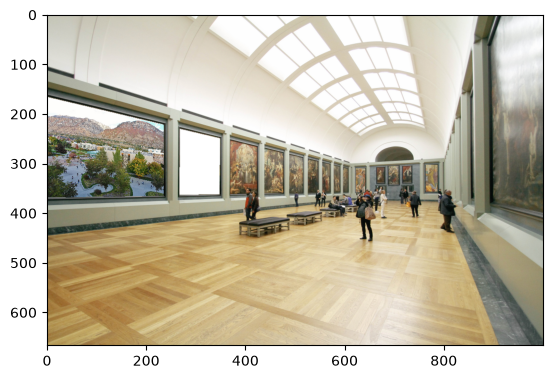

Slow Method: 10.451797723770142


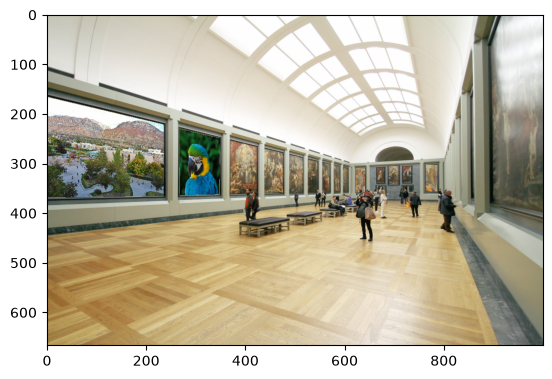

Fast Method: 0.6005964279174805


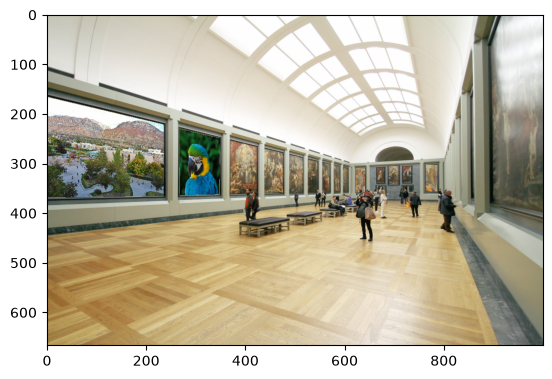

In [33]:
#def composeFast(Whatever inputs you may need):   
#    return None

def composeFast(source_im, target_im, transform, t0, t1, t2, t3):
    hs, ws, _ = source_im.shape
    ht, wt, _ = target_im.shape
    result = np.copy(target_im)

    invtransform = np.linalg.inv(transform)

    xs = [t0.x, t1.x, t2.x, t3.x]
    ys = [t0.y, t1.y, t2.y, t3.y]
    xmin = max(0, int(np.amin(xs)))
    xmax = min(wt, int(np.amax(xs)) + 1)
    ymin = max(0, int(np.amin(ys)))
    ymax = min(ht, int(np.amax(ys)) + 1)

    # Only visit pixels that could possibly map inside the source image
    for i in range(ymin, ymax):
        for j in range(xmin, xmax):
            h_pt = np.matrix([[j],[i],[1]])
            c_pt = invtransform*h_pt
            x = c_pt[0,0]/c_pt[2,0]
            y = c_pt[1,0]/c_pt[2,0]

            if x < 0 or x >= ws or y < 0 or y >= hs:
                continue

            result[i,j] = interpolate(source_im, x, y)

    return result

def perspectiveWarpFast(source_im,target_im,s0,s1,s2,s3,t0,t1,t2,t3):
    
    #result = np.copy(target_im)
    H = getHomography(s0,s1,s2,s3,t0,t1,t2,t3)
    # 2. Compose, but only inside the target bounding box
    result = composeFast(source_im, target_im, H, t0, t1, t2, t3)
    
    return result
    

from time import time
    
museum = plt.imread('museum.png')
plt.imshow(museum,vmin=0)
plt.show()

filename = "test.png"
im = plt.imread(filename)

h,w,_ = im.shape
        
s0 = Point(0,0)
s1 = Point(w-1,0)
s2 = Point(w-1,h-1)
s3 = Point(0,h-1)

t0 = Point(268,230)
t1 = Point(349,249)
t2 = Point(347,361)
t3 = Point(267,363)

#Points for nearest canvas
#t0 = Point(0,170)
#t1 = Point(235,222)
#t2 = Point(236,365)
#t3 = Point(0,368)


start = time()
result1 = perspectiveWarp(im,museum,s0,s1,s2,s3,t0,t1,t2,t3)
print("Slow Method:",time()-start)

plt.imshow(result1,vmin=0)
plt.show()

start = time()
result2 = perspectiveWarpFast(im,museum,s0,s1,s2,s3,t0,t1,t2,t3)
print("Fast Method:",time()-start)

#plt.imsave("Output.png",result2)
plt.imshow(result2,vmin=0)
plt.show()

The run time for the slow method is 9.690612077713013, and is way higher than the time used when the compose function only checks pixels in the relevant bounding box in the image. The reduced run time is 0.5865163803100586.


# Part 4: QR Code Reader

We now have all the basic building blocks to make our own QR code reader. You will implement one for the last part of the lab. We will focus primarily the computer vision side of QR codes, which involves detecting, aligning, and discretizing QR codes so that they can be read properly.

### Understanding QR Codes

QR codes (short for Quick Response Codes) were invented in 1994, by the DENSO Corporation. These codes store data in two dimensions in the form of an array of contrasting regions. The information density of a QR code is much higher than a vanilla barcode; depending on the format used and the resolution of reader, over a thousand bytes can be encoded in a region the size of a postage stamp.

QR codes use a Reed–Solomon error correction based technology to help recover from errors in reading (for instance, caused by a smudge, badly printed code or other deformity).

Any QR code can be broken into the following sections:

<div style="width:60%;text-align:center;"><img src="qr-code-images/formatting.jpg" width=100%></div>

On three corners of a QR code are square blocks that the reader uses to coarsely identify and then align the code. These position markers always have a black/white/black/white/black ratio of 1:1:3:1:1, no matter the angle they are approached from.

<div style="width:30%;text-align:center;"><img src="qr-code-images/finder_pattern.jpg" width=100%></div>

The fourth point is called the alignment point and has a slightly different pattern and location. This allows the QR code to be properly oriented. Some smaller QR codes do not have this alignment block, so they approximate this location using an affine transform of the three given points.

Once these four points are identified, the image can be aligned using a homography and warping. The number of rows and columns in the QR code is determined by the timing information which alternates from black and white in both the vertical and horizontal direction.

Once the image is aligned and the size determined, the QR code is discretized, undergoes an Xor with a particular mask given the format information, and read bit for bit in the following order:

<div style="width:60%;text-align:center;"><img src="qr-code-images/decoding.jpg" width=100%></div>

For more details about the decoding process, see the [DataGenetics Wounded QR Codes Blog](http://datagenetics.com/blog/november12013/index.html).


### Implementation

You will be implementing a QR code reader for 29x29 QR codes. The very first step of identifying the three corners using the 1:1:3:1:1 ratio has been implemented for you. For simplicity, the code does not return a fourth alignment point, but rather returns an axis-aligned point as if a corner was present, as shown in the figure.

<div style="width:40%;text-align:center;"><img src="qr-code-images/keypoints.png" width=100%></div>

The very last step of taking a NumPy array of 1's and 0's and decoding it using the QR code standard has also been implemented for you. Your task is to implement everything inbetween.

To implement the QR code reader for a given input image:

- Feed the image into the provided `getCornerPoints` function to the get the x,y coordinates of the four corners.
- Use your `perspectiveWarp` to map the four points to an axis-aligned square centered on a 29x29 blank image (sometimes called a buffer or canvas).
- Discretize/threshold the image into True/False values.
- Feed the 29x29 grid into the provided `decode` function. A string will be returned with the QR code URL data.

**Remember that the locations of corners are not on the edge, but 4 pixels in on the 29x29 grid.** Once you have implemented the code, run it on the test cases below.

The decoder function depends on the OpenCV package. You may need to `pip install opencv-python` if the decoder doesn't run properly.

**Note: You are not allowed to directly use OpenCV's QR Code functions for this lab.**


In [ ]:
from qr import getCornerPoints, decode
import io, contextlib

# def scanQRcode(image):

#     # Your Code Here

#     return None

def scanQRcode(image):
    # --- 0. Normalize source image for warping ---
    if image.ndim == 3 and image.shape[2] == 4:
        source_im = image[:, :, :3]
    else:
        source_im = image
    # Work in float32 0-1 like the rest of the lab
    source_im = source_im.astype(np.float32)
    if np.amax(source_im) > 1.5:  # guard against 0-255 uint8 loads
        source_im = source_im / 255.0

    # --- 1. Detect the four corners (TL, TR, BL, BR per FAQ) ---
    pts = getCornerPoints(image)
    s0, s1, s2, s3 = pts[0], pts[1], pts[2], pts[3]

    # --- 2/3. Try each plausible QR size (21..41 step 4). ---
    for N in [21, 25, 29, 33, 37, 41]:
        # Blank canvas: same dtype (float32) as image, RGB channels (FAQ)
        canvas = np.zeros((N, N, 3), dtype=np.float32)

        # Target points: finder centers, 4th pixel in (index 3)
        inset = 3
        t0 = Point(inset, inset)                 # top-left
        t1 = Point(N-1-inset, inset)             # top-right
        t2 = Point(inset, N-1-inset)             # bottom-left
        t3 = Point(N-1-inset, N-1-inset)         # bottom-right

        # Warp: source=photo, target=canvas. Do NOT swap (FAQ).
        warped = perspectiveWarp(source_im, canvas, s0, s1, s2, s3, t0, t1, t2, t3)

        # --- 4. Collapse RGB -> grayscale, then discretize ---
        gray = np.mean(warped, axis=2)           # 2D grid, no color channels (FAQ)
        binary = (gray > 0.5).astype(bool)       # True=white, False=black; bool dtype (FAQ)


        with contextlib.redirect_stdout(io.StringIO()):
            code = decode(binary)
        if code:  # non-empty string means success
            return code

    # If no size decoded, return None
    return None


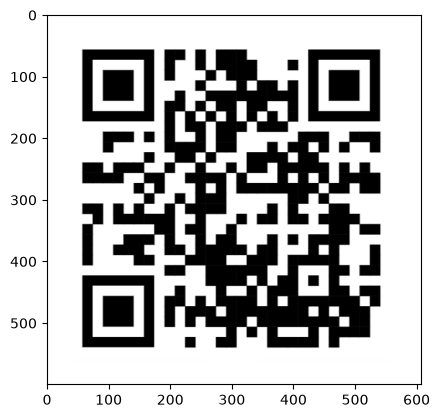

https://ecu.edu


In [39]:
image1 = plt.imread("qr-code-images/test1.png")
plt.imshow(image1);plt.show()
code1 = scanQRcode(image1)
print(code1)

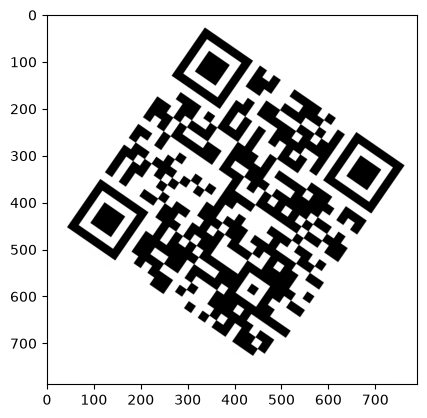

https://davidhartcv.com


In [40]:
image2 = plt.imread("qr-code-images/test2.png")
plt.imshow(image2);plt.show()
code2 = scanQRcode(image2)
print(code2)

### Extra Credit: Any Size QR Code Reader (10 pts)

The QR code reader you implemented will work for 29x29 QR codes, but QR codes can be many sizes. All QR codes have an odd number of bits per row and column and go up by 4, starting at size 21 (i.e. 21x21, 25x25, 29x29, ...). For 5 points extra credit, implement a QR code reader that works for any size from 21x21 up to 41x41.

To check if a QR code matches a given size, discretize the QR code asumming a 21x21 size. Then, determine if the timing information alternates in the appropriate manner (see the Understanding QR Codes for more information). If the timing information is valid, then you can assume that the QR code is the given size. If not, move up to the next size (25x25) and repeat.

You can check if your any-size QR code reader is working by running the following test case.


shape: (800, 804, 4)


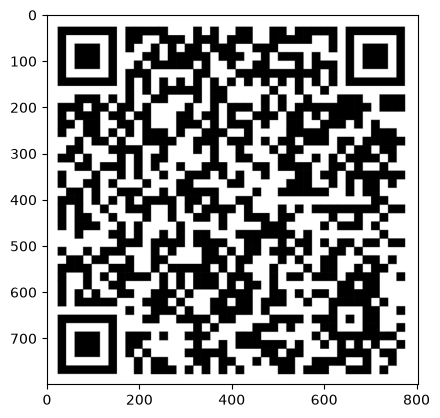

https://cet.ecu.edu/csci/about-us/faculty-staff/hart/


In [41]:
image_ec = plt.imread("qr-code-images/extra_credit.png")
print("shape:", image_ec.shape)
plt.imshow(image_ec);plt.show()
code_ec = scanQRcode(image_ec)
print(code_ec)